# Homework 4 — Stock Prediction and Trading Strategy

**UC Berkeley MFE | Jordyn Paszamant**

Predict 90-calendar-day stock returns and evaluate a long-only strategy against the S&P 500 Total Return index from April 1, 2016 through September 30, 2026.

**Run instructions.** From the course repository root, run `uv sync --locked` and select the repository's `.venv` as the notebook kernel. Download `equities_top2000.duckdb` from bCourses into `Lectures/modeling/data/`. The notebook also supports the existing HW4-local `data/` location. Open the notebook from within the repository and run all cells. The first run builds a Parquet cache in the notebook folder's ignored `processed_features/` directory. Allow time for the feature build and 11 model fits. The database is opened read-only. Delete the cache for a fresh feature build.

**Strategy.** Eight price-based features, a Random Forest, an expanding training window with annual refits, and up to five positive forecasts every 21 market sessions. Signals and dollar budgets are set after the signal close for entry at the next session's close. The strategy holds for 90 calendar days, trades long only, pays 0.10% per side, and earns zero interest on cash.

In [1]:
from pathlib import Path
import gc

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Find the course root from either the notebook folder or the repository root.
cwd = Path.cwd()
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "Lectures/modeling").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start the notebook kernel inside the course repository.")

homework_dir = repo_root / "Homeworks/HW4/Jordyn_Paszamant"
database_name = "equities_top2000.duckdb"
database_paths = [
    repo_root / "Lectures/modeling/data" / database_name,
    homework_dir / "data" / database_name,
]
full_db = next((p for p in database_paths if p.is_file()), None)
if full_db is None:
    raise FileNotFoundError(f"Download {database_name} to {database_paths[0].parent}")

full_con = duckdb.connect(str(full_db), read_only=True)
feature_columns = [
    "momentum_21", "momentum_63", "momentum_126", "momentum_252",
    "volatility_21", "volatility_63", "ma_ratio_50", "ma_ratio_200",
]
print("Full dataset connected:", full_db.relative_to(repo_root))

Full dataset connected: Homeworks/HW4/Jordyn_Paszamant/data/equities_top2000.duckdb


## 1. Feature engineering and historical trading universe

Momentum at 21, 63, 126, and 252 sessions captures recent and longer-term trends. Daily-return volatility over 21 and 63 sessions measures how variable those returns were. Adjusted close relative to its 50- and 200-session moving averages measures how far the stock has moved from recent price levels. All eight features are available at the signal close. The model uses no company financial statements as direct inputs.

Compute features on the supplied market calendar in 100-symbol batches. Missing and invalid prices stay missing and off-calendar rows are excluded. Momentum requires observed prices at both endpoints. Rolling volatility and moving averages require complete windows. Use the historical membership in effect on the **entry** date to select candidates. Keep the complete quote history for existing holdings after they leave the universe.

In [2]:
# A separate cache version prevents reuse of pre-calendar feature batches.
FEATURE_DIR = homework_dir / "processed_features" / "market_calendar_v1"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
database_stat = full_db.stat()
cache_key = f"{full_db}:{database_stat.st_size}:{database_stat.st_mtime_ns}"
cache_stamp = FEATURE_DIR / "database.txt"

full_calendar = full_con.execute("SELECT date FROM calendar ORDER BY date").df()
full_calendar["date"] = pd.to_datetime(full_calendar["date"])
market_dates = pd.DatetimeIndex(full_calendar["date"], name="date")

price_audit = full_con.execute(
    """
    SELECT COUNT(*) FILTER (WHERE c.date IS NULL) AS off_calendar_rows,
           COUNT(*) FILTER (WHERE p.adj_close IS NULL OR p.adj_close <= 0
                              OR NOT isfinite(p.adj_close)) AS invalid_price_rows
    FROM prices p
    LEFT JOIN calendar c ON c.date = p.date
    """
).df()
display(price_audit)

# Get all stock symbols
all_symbols = full_con.execute("""
    SELECT DISTINCT symbol
    FROM prices
    ORDER BY symbol
""").df()["symbol"].tolist()

batch_size = 100

symbol_batches = [
    all_symbols[i:i + batch_size]
    for i in range(0, len(all_symbols), batch_size)
]

print("Total stocks:", len(all_symbols))
print("Number of batches:", len(symbol_batches))
print("Stocks in first batch:", len(symbol_batches[0]))

def build_price_features(df):

    df = df.sort_values(["symbol", "date"]).copy()
    df["date"] = pd.to_datetime(df["date"])

    # Insert missing sessions before measuring lags or rolling windows.
    observed_index = pd.MultiIndex.from_frame(df[["symbol", "date"]])
    batch_index = pd.MultiIndex.from_product(
        [df["symbol"].unique(), market_dates], names=["symbol", "date"]
    )
    df = df.set_index(["symbol", "date"]).reindex(batch_index).reset_index()

    # Only positive, finite adjusted prices are valid.
    df["adj_close"] = df["adj_close"].where(
        np.isfinite(df["adj_close"]) & (df["adj_close"] > 0)
    )

    grouped = df.groupby("symbol")["adj_close"]

    # Daily returns and momentum
    df["daily_return"] = grouped.pct_change(fill_method=None)

    for n in [21, 63, 126, 252]:
        df[f"momentum_{n}"] = grouped.pct_change(
            periods=n,
            fill_method=None
        )

    # Rolling volatility
    for n in [21, 63]:
        df[f"volatility_{n}"] = (
            df.groupby("symbol")["daily_return"]
            .transform(
                lambda x: x.rolling(n, min_periods=n).std()
            )
        )

    # Moving-average ratios
    for n in [50, 200]:
        moving_avg = grouped.transform(
            lambda x: x.rolling(n, min_periods=n).mean()
        )

        df[f"ma_ratio_{n}"] = (
            df["adj_close"] / moving_avg - 1
        )

    # Only original on-calendar observations need to be written to disk.
    return df.set_index(["symbol", "date"]).loc[observed_index].reset_index()

# Rebuild if the database changed or a previous build did not complete.
files = [FEATURE_DIR / f"features_batch_{i:02d}.parquet" for i in range(len(symbol_batches))]
cache_valid = (
    cache_stamp.is_file()
    and cache_stamp.read_text() == cache_key
    and all(path.is_file() for path in files)
)
if not cache_valid:
    cache_stamp.unlink(missing_ok=True)
    for batch, batch_file in zip(symbol_batches, files):
        frame = full_con.execute(
            """
            SELECT p.symbol, p.date, p.adj_close
            FROM prices p
            JOIN calendar c ON p.date = c.date
            WHERE p.symbol IN (SELECT UNNEST(?))
            ORDER BY p.symbol, p.date
            """,
            [batch],
        ).df()
        build_price_features(frame).to_parquet(batch_file, index=False)
        del frame
        gc.collect()
    cache_stamp.write_text(cache_key)

print(f"Feature cache: {len(files)} batches for {len(all_symbols):,} stocks")

Total stocks: 3849
Number of batches: 39
Stocks in first batch: 100
Feature cache: 39 batches for 3,849 stocks


,off_calendar_rows,invalid_price_rows
0,28,275


In [3]:
full_con.execute("SET VARIABLE feature_paths = ?", [[str(path) for path in files]])
full_con.execute(
    "CREATE OR REPLACE TEMP VIEW stock_features AS "
    "SELECT * FROM read_parquet(getvariable('feature_paths'))"
)
print("Feature view created successfully.")

display(
    full_con.execute("""
        SELECT symbol, date, adj_close, momentum_252
        FROM stock_features
        LIMIT 5
    """).df()
)

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW market_sessions AS
    SELECT
        date AS signal_date,
        LEAD(date) OVER (ORDER BY date) AS entry_date
    FROM calendar
""")

print("Market session lookup created successfully.")

display(
    full_con.execute("""
        SELECT *
        FROM market_sessions
        WHERE signal_date BETWEEN '2016-03-28' AND '2016-04-08'
        ORDER BY signal_date
    """).df()
)

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW eligible_features AS
    SELECT p.*, c.entry_date
    FROM stock_features p
    JOIN market_sessions c ON c.signal_date = p.date
    WHERE EXISTS (
        SELECT 1
        FROM universe_membership m
        WHERE p.symbol = m.symbol
          AND c.entry_date BETWEEN m.effective_start AND m.quarter_end
    )
""")
print("Historical entry-quarter eligibility view created successfully.")

# Audit two extreme ranking inputs identified in the course data guide.
display(full_con.execute("""
    SELECT symbol, quarter_start, selection_close, selection_shares,
           market_cap_proxy, universe_rank
    FROM universe_membership
    WHERE quarter_start = '2010-01-01' AND symbol IN ('APDN', 'TSYS')
    ORDER BY universe_rank
""").df())

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW valid_quotes AS
    SELECT symbol, date, adj_close
    FROM stock_features
    WHERE adj_close > 0
      AND isfinite(adj_close)
""")

print("Valid price view created successfully.")

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW target_entries AS
    SELECT
        p.*,
        e.adj_close AS entry_price,
        CAST(
            p.entry_date + INTERVAL 90 DAY AS DATE
        ) AS maturity_date
    FROM eligible_features p
    LEFT JOIN valid_quotes e
        ON p.symbol = e.symbol
       AND p.entry_date = e.date
""")

print("Entry dates and prices prepared.")

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW full_targets AS
    SELECT
        p.*,
        q.date AS exit_date,
        q.adj_close AS exit_price,
        CASE
            WHEN p.entry_price > 0
             AND q.adj_close > 0
            THEN q.adj_close / p.entry_price - 1
            ELSE NULL
        END AS return_90d
    FROM target_entries p
    ASOF LEFT JOIN valid_quotes q
        ON p.symbol = q.symbol
       AND p.maturity_date <= q.date
""")

print("90-day target view created successfully.")

# Verify the lookup mechanics without loading the full target table.
timing = full_con.execute("""
    SELECT COUNT(*) FILTER (WHERE exit_date < maturity_date) AS early_exits,
           COUNT(*) FILTER (WHERE entry_date <= date) AS early_entries
    FROM full_targets WHERE date BETWEEN '2010-01-01' AND '2015-12-31'
""").df()
assert timing.iloc[0].fillna(0).eq(0).all()
print("Target timing check passed:", timing.to_dict("records")[0])

Feature view created successfully.
Market session lookup created successfully.
Historical entry-quarter eligibility view created successfully.
Valid price view created successfully.
Entry dates and prices prepared.
90-day target view created successfully.
Target timing check passed: {'early_exits': 0, 'early_entries': 0}


,symbol,date,adj_close,momentum_252
0,A,2000-01-03,40.30,NaN
1,A,2000-01-04,36.69,NaN
2,A,2000-01-05,34.92,NaN
3,A,2000-01-06,33.02,NaN
4,A,2000-01-07,36.38,NaN


,signal_date,entry_date
0,2016-03-28,2016-03-29
1,2016-03-29,2016-03-30
2,2016-03-30,2016-03-31
3,2016-03-31,2016-04-01
4,2016-04-01,2016-04-04
5,2016-04-04,2016-04-05
6,2016-04-05,2016-04-06
7,2016-04-06,2016-04-07
8,2016-04-07,2016-04-08
9,2016-04-08,2016-04-11


,symbol,quarter_start,selection_close,selection_shares,market_cap_proxy,universe_rank
0,TSYS,2010-01-01,9.68,4.686500e+10,4.536532e+11,1
1,APDN,2010-01-01,2232000.15,1.502260e+05,3.353045e+11,2


The 2010 Q1 membership ranks TSYS first with 46.865 billion recorded shares and APDN second with a recorded close above $2.2 million. Those inputs can inflate the capitalization proxy and displace other stocks. The course guide identifies possible unit, split, and share-class mismatches. I keep the supplied membership because the data do not establish corrected values. Historical membership includes inactive names, and incomplete ticker and delisting coverage can still bias the sample.

## 2. Development evidence and training targets

In the earlier classroom experiment, I fit on signals from 2010–2013 whose labels ended before January 1, 2014. I compared Ridge and Random Forest on the same April–December 2014 holdout, within the development period.

| Model | RMSE | Mean daily Spearman rank correlation |
| --- | ---: | ---: |
| Ridge | 0.1543 | −0.1540 |
| Random Forest | 0.1379 | 0.0436 |

The forest can capture nonlinear relationships among the price indicators. It ranked stocks better than Ridge in the classroom holdout, which mattered for the top-five rule. Its rank correlation was still small, and the classroom extract only contains 30 names. These saved development results are from the earlier prototype, which used signal-quarter membership and observed-row lookbacks. The full run below uses the corrected entry-quarter and market-calendar definitions. The corrected run retains the forest settings and annual expanding-window refit from my earlier full-data notebook. The classroom holdout compares model types. The timing of the original refit-schedule decision is undocumented.

For each signal, the target is the next session's entry close to the first observed market-session close on or after 90 calendar days. Targets with no executable entry or exit remain unavailable, but their missingness does not screen live candidates. Training is sampled every 21 sessions. The jump screen flags an observed price ratio above 5× or below 0.2×. It screens live candidates only on information through the signal date. For completed labels, it also screens the observed interval through the exit. The screen flags discontinuities and does not establish what caused them.

In [4]:
training_calendar = full_con.execute("""
    SELECT date
    FROM calendar
    WHERE date BETWEEN '2010-01-01' AND '2015-12-31'
    ORDER BY date
""").df()

training_dates = training_calendar.iloc[::21].copy()

full_con.register("training_dates", training_dates)

print("Training signal dates:", len(training_dates))

display(training_dates.head())
display(training_dates.tail())

full_train = full_con.execute("""
    SELECT
        t.symbol,
        t.date,
        t.exit_date,
        t.momentum_21,
        t.momentum_63,
        t.momentum_126,
        t.momentum_252,
        t.volatility_21,
        t.volatility_63,
        t.ma_ratio_50,
        t.ma_ratio_200,
        t.return_90d
    FROM full_targets t
    INNER JOIN training_dates d
        ON t.date = d.date
    WHERE t.exit_date < '2016-04-01'
      AND t.return_90d IS NOT NULL
      AND isfinite(t.return_90d)
      AND t.momentum_21 IS NOT NULL
      AND t.momentum_63 IS NOT NULL
      AND t.momentum_126 IS NOT NULL
      AND t.momentum_252 IS NOT NULL
      AND t.volatility_21 IS NOT NULL
      AND t.volatility_63 IS NOT NULL
      AND t.ma_ratio_50 IS NOT NULL
      AND t.ma_ratio_200 IS NOT NULL
""").df()

print("Training observations:", len(full_train))
print("Unique stocks:", full_train["symbol"].nunique())
print("First signal date:", full_train["date"].min())
print("Last signal date:", full_train["date"].max())
print("Latest completed exit:", full_train["exit_date"].max())

full_con.execute("""
    CREATE OR REPLACE TEMP VIEW price_quality AS
    WITH returns AS (
        SELECT
            symbol,
            date,
            adj_close,
            LAG(adj_close) OVER (
                PARTITION BY symbol ORDER BY date
            ) AS previous_price
        FROM valid_quotes
    )
    SELECT
        *,
        adj_close / previous_price AS price_ratio,
        CASE
            WHEN previous_price > 0
             AND (
                 adj_close / previous_price > 5
                 OR adj_close / previous_price < 0.2
             )
            THEN 1
            ELSE 0
        END AS extreme_jump
    FROM returns
""")

print("Price-quality flags created.")

flagged_dates = full_con.execute("""
    SELECT symbol, date
    FROM price_quality
    WHERE extreme_jump = 1
    ORDER BY symbol, date
""").df()

flagged_dates["date"] = pd.to_datetime(flagged_dates["date"])

print("Flagged observations:", len(flagged_dates))
print("Affected stocks:", flagged_dates["symbol"].nunique())

# Work with a copy of our original training sample
train_quality = full_train.copy()

train_quality["date"] = pd.to_datetime(train_quality["date"])
train_quality["exit_date"] = pd.to_datetime(train_quality["exit_date"])

flag_lookup = {
    symbol: group["date"].to_numpy(dtype="datetime64[ns]")
    for symbol, group in flagged_dates.groupby("symbol")
}

train_quality["historical_flag"] = False
train_quality["target_flag"] = False

for symbol, idx in train_quality.groupby("symbol").groups.items():

    if symbol not in flag_lookup:
        continue

    flags = flag_lookup[symbol]

    signal = train_quality.loc[idx, "date"].to_numpy(
        dtype="datetime64[ns]"
    )

    exit_dates = train_quality.loc[idx, "exit_date"].to_numpy(
        dtype="datetime64[ns]"
    )

    lookback_start = signal - np.timedelta64(400, "D")

    # Flags visible before or on the signal date
    historical_count = (
        np.searchsorted(flags, signal, side="right")
        - np.searchsorted(flags, lookback_start, side="left")
    )

    # Flags during the subsequent holding period
    target_count = (
        np.searchsorted(flags, exit_dates, side="right")
        - np.searchsorted(flags, signal, side="right")
    )

    train_quality.loc[idx, "historical_flag"] = historical_count > 0
    train_quality.loc[idx, "target_flag"] = target_count > 0

# Exclude flagged training observations
clean_train = train_quality[
    ~train_quality["historical_flag"] &
    ~train_quality["target_flag"]
].copy()

print("Original training observations:", len(full_train))
print("Historical lookback flags:", train_quality["historical_flag"].sum())
print("Holding-period flags:", train_quality["target_flag"].sum())
print("Clean training observations:", len(clean_train))
print("Observations excluded:", len(full_train) - len(clean_train))

print(f"Development training observations: {len(clean_train):,} (excluded {len(full_train) - len(clean_train):,})")
assert (clean_train["date"] < pd.Timestamp("2016-01-01")).all()
assert (clean_train["exit_date"] < pd.Timestamp("2016-04-01")).all()

Training signal dates: 72
Training observations: 137001
Unique stocks: 2365
First signal date: 2010-01-04 00:00:00
Last signal date: 2015-12-04 00:00:00
Latest completed exit: 2016-03-07 00:00:00
Price-quality flags created.
Flagged observations: 1980
Affected stocks: 277
Original training observations: 137001
Historical lookback flags: 273
Holding-period flags: 75
Clean training observations: 136687
Observations excluded: 314
Development training observations: 136,687 (excluded 314)


,date
0,2010-01-04
21,2010-02-03
42,2010-03-05
63,2010-04-06
84,2010-05-05


,date
1407,2015-08-06
1428,2015-09-04
1449,2015-10-06
1470,2015-11-04
1491,2015-12-04


In [5]:
test_start = pd.Timestamp("2016-04-01")
test_end = pd.Timestamp("2026-09-30")

test_calendar = full_calendar[
    full_calendar["date"].between(test_start, test_end)
].reset_index(drop=True)

test_signal_dates = test_calendar.iloc[::21].copy()

print("Total test trading sessions:", len(test_calendar))
print("Scheduled signal dates:", len(test_signal_dates))
print("First signal date:", test_signal_dates["date"].min())
print("Last scheduled signal date:", test_signal_dates["date"].max())

display(test_signal_dates.head())
display(test_signal_dates.tail())

full_con.register("test_signal_dates", test_signal_dates)
full_con.register("quality_flag_dates", flagged_dates)

test_candidates = full_con.execute("""
    SELECT
        p.symbol,
        p.date,
        p.entry_date,
        p.adj_close,
        p.momentum_21,
        p.momentum_63,
        p.momentum_126,
        p.momentum_252,
        p.volatility_21,
        p.volatility_63,
        p.ma_ratio_50,
        p.ma_ratio_200
    FROM eligible_features p
    JOIN test_signal_dates d
      ON p.date = d.date
    WHERE p.entry_date <= DATE '2026-09-30'
      AND p.adj_close > 0
      AND isfinite(p.adj_close)
      AND NOT EXISTS (
          SELECT 1
          FROM quality_flag_dates f
          WHERE f.symbol = p.symbol
            AND f.date BETWEEN
                p.date - INTERVAL 400 DAY AND p.date
      )
""").df()

test_candidates["date"] = pd.to_datetime(test_candidates["date"])
test_candidates["entry_date"] = pd.to_datetime(
    test_candidates["entry_date"]
)

test_candidates = (
    test_candidates.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=feature_columns)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

print("Total signal candidates:", len(test_candidates))
print("Unique stocks:", test_candidates["symbol"].nunique())
print("Signal dates represented:", test_candidates["date"].nunique())

retrain_dates = (
    test_signal_dates
    .groupby(test_signal_dates["date"].dt.year)["date"]
    .min()
    .tolist()
)

print("Number of annual model updates:", len(retrain_dates))

display(
    pd.DataFrame({
        "Retraining Date": retrain_dates
    })
)

future_outcomes = full_con.execute("""
    SELECT
        t.symbol,
        t.date,
        t.exit_date,
        t.return_90d
    FROM full_targets t
    JOIN test_signal_dates d
      ON t.date = d.date
    WHERE t.date >= DATE '2016-04-01'
      AND t.exit_date <= DATE '2026-09-30'
""").df()

future_outcomes["date"] = pd.to_datetime(
    future_outcomes["date"]
)

future_outcomes["exit_date"] = pd.to_datetime(
    future_outcomes["exit_date"]
)

# Match outcomes to historically eligible, quality-screened candidates
future_train = test_candidates[
    ["symbol", "date"] + feature_columns
].merge(
    future_outcomes,
    on=["symbol", "date"],
    how="left",
    validate="one_to_one"
)

future_train = future_train[
    np.isfinite(future_train["return_90d"]) &
    future_train["exit_date"].notna()
].copy()

print("Additional completed outcomes:", len(future_train))
print("Latest available exit date:", future_train["exit_date"].max())

future_train["target_flag"] = False

for symbol, idx in future_train.groupby("symbol").groups.items():

    if symbol not in flag_lookup:
        continue

    flags = flag_lookup[symbol]

    signal_dates = future_train.loc[idx, "date"].to_numpy(
        dtype="datetime64[ns]"
    )

    exit_dates = future_train.loc[idx, "exit_date"].to_numpy(
        dtype="datetime64[ns]"
    )

    flag_count = (
        np.searchsorted(flags, exit_dates, side="right")
        - np.searchsorted(flags, signal_dates, side="right")
    )

    future_train.loc[idx, "target_flag"] = flag_count > 0

future_train = future_train[
    ~future_train["target_flag"]
].copy()

# Combine initial development data with later completed outcomes
training_columns = [
    "symbol", "date", "exit_date",
    "return_90d"
] + feature_columns

walk_forward_pool = pd.concat(
    [
        clean_train[training_columns],
        future_train[training_columns]
    ],
    ignore_index=True
)

walk_forward_pool = walk_forward_pool.sort_values(
    ["date", "symbol"]
).reset_index(drop=True)

print("Initial development observations:", len(clean_train))
print("Additional screened observations:", len(future_train))
print("Total potential training observations:", len(walk_forward_pool))

# Confirm that each stock-date appears at most once
assert not walk_forward_pool.duplicated(
    ["symbol", "date"]
).any()

print("Training pool verified.")

assert not walk_forward_pool.duplicated(["symbol", "date"]).any()
print(f"Walk-forward pool: {len(walk_forward_pool):,} observations; {len(retrain_dates)} refits")

Total test trading sessions: 2640
Scheduled signal dates: 126
First signal date: 2016-04-01 00:00:00
Last scheduled signal date: 2026-09-10 00:00:00
Total signal candidates: 241944
Unique stocks: 3313
Signal dates represented: 126
Number of annual model updates: 11
Additional completed outcomes: 234531
Latest available exit date: 2026-09-09 00:00:00
Initial development observations: 136687
Additional screened observations: 234428
Total potential training observations: 371115
Training pool verified.
Walk-forward pool: 371,115 observations; 11 refits


,date
0,2016-04-01
21,2016-05-02
42,2016-06-01
63,2016-06-30
84,2016-08-01


,date
2541,2026-05-11
2562,2026-06-10
2583,2026-07-13
2604,2026-08-11
2625,2026-09-10


,Retraining Date
0,2016-04-01
1,2017-01-31
2,2018-01-31
3,2019-01-02
4,2020-01-02
5,2021-02-02
6,2022-02-01
7,2023-01-03
8,2024-01-04
9,2025-01-06


## 3. Walk-forward prediction and stock selection

At the first signal of each calendar year, fit the fixed Random Forest on signals and exits strictly before the fit date. Use the buffer for completed labels from late-2015 signals. The first fit uses only development signals. Later fits add eligible, completed outcomes from past test signals. Recompute 1st and 99th percentile clipping thresholds from each training sample and use those thresholds on the new candidates. The forest uses 200 trees, depth 6, minimum leaf size 100, and seed 42. Rank by predicted return and shortlist up to five positive forecasts per signal.

In [6]:
all_predictions = []
model_history = []

for i, retrain_date in enumerate(retrain_dates):

    retrain_date = pd.Timestamp(retrain_date)

    if i + 1 < len(retrain_dates):
        next_retrain = pd.Timestamp(retrain_dates[i + 1])
    else:
        next_retrain = test_end + pd.Timedelta(days=1)

    # Training outcomes must be completed before retraining
    train_now = walk_forward_pool[
        (walk_forward_pool["date"] < retrain_date) &
        (walk_forward_pool["exit_date"] < retrain_date)
    ].copy()

    assert not train_now.empty
    assert (train_now["exit_date"] < retrain_date).all()

    # Learn clipping thresholds from this training sample only
    lower = train_now[feature_columns].quantile(0.01)
    upper = train_now[feature_columns].quantile(0.99)

    X = train_now[feature_columns].clip(
        lower=lower,
        upper=upper,
        axis=1
    )

    y_lower = train_now["return_90d"].quantile(0.01)
    y_upper = train_now["return_90d"].quantile(0.99)

    y = train_now["return_90d"].clip(
        lower=y_lower,
        upper=y_upper
    )

    # Train the annual Random Forest
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X, y)

    # Score only signals covered by this trained model
    candidates_now = test_candidates[
        (test_candidates["date"] >= retrain_date) &
        (test_candidates["date"] < next_retrain)
    ].copy()

    X_predict = candidates_now[feature_columns].clip(
        lower=lower,
        upper=upper,
        axis=1
    )

    candidates_now["predicted_return"] = model.predict(X_predict)
    candidates_now["model_date"] = retrain_date

    all_predictions.append(candidates_now)

    model_history.append({
        "model_date": retrain_date,
        "training_observations": len(train_now),
        "latest_training_exit": train_now["exit_date"].max(),
        "predictions": len(candidates_now)
    })

    print(
        f"{retrain_date.date()}: "
        f"{len(train_now):,} training observations, "
        f"{len(candidates_now):,} predictions"
    )

    del model, train_now, X, y, X_predict, candidates_now
    gc.collect()

walk_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

model_history = pd.DataFrame(model_history)

print("\nWalk-forward prediction process completed.")

assert (model_history["latest_training_exit"] < model_history["model_date"]).all()
print("Annual training cutoffs verified.")

2016-04-01: 136,687 training observations, 19,386 predictions
2017-01-31: 152,134 training observations, 23,187 predictions
2018-01-31: 175,336 training observations, 21,184 predictions
2019-01-02: 196,512 training observations, 23,052 predictions
2020-01-02: 217,658 training observations, 24,615 predictions
2021-02-02: 244,271 training observations, 21,925 predictions
2022-02-01: 266,172 training observations, 20,966 predictions
2023-01-03: 284,663 training observations, 23,635 predictions
2024-01-04: 309,949 training observations, 23,422 predictions
2025-01-06: 331,200 training observations, 23,193 predictions
2026-01-08: 355,974 training observations, 17,379 predictions

Walk-forward prediction process completed.
Annual training cutoffs verified.


In [7]:
walk_predictions = walk_predictions.sort_values(
    ["date", "predicted_return", "symbol"],
    ascending=[True, False, True]
).copy()

walk_predictions["rank"] = (
    walk_predictions.groupby("date").cumcount() + 1
)

final_buy_signals = walk_predictions[
    (walk_predictions["rank"] <= 5) &
    (walk_predictions["predicted_return"] > 0)
].copy()

print("Signal dates:", final_buy_signals["date"].nunique())
print("Candidate purchases:", len(final_buy_signals))
print("Unique stocks selected:", final_buy_signals["symbol"].nunique())

display(
    final_buy_signals[
        ["date", "symbol", "predicted_return",
         "rank", "entry_date", "model_date"]
    ].head(15).round(4)
)

print(
    "All signals precede execution:",
    (final_buy_signals["date"] < final_buy_signals["entry_date"]).all()
)

print(
    "All models available before signals:",
    (final_buy_signals["model_date"] <= final_buy_signals["date"]).all()
)

print(
    "Maximum candidate purchases per signal:",
    final_buy_signals.groupby("date").size().max()
)

print(
    "Duplicate stock-date signals:",
    final_buy_signals.duplicated(["symbol", "date"]).sum()
)

assert (final_buy_signals["date"] < final_buy_signals["entry_date"]).all()
assert (final_buy_signals["model_date"] <= final_buy_signals["date"]).all()
assert final_buy_signals.groupby("date").size().max() <= 5
assert not final_buy_signals.duplicated(["symbol", "date"]).any()

print("Trading signal checks passed.")

print(f"Signals: {final_buy_signals['date'].nunique()} dates, {len(final_buy_signals)} buy candidates")
display(model_history[["model_date", "training_observations", "latest_training_exit"]])

full_con.register("selected_signals", final_buy_signals[["symbol", "entry_date"]])
ineligible_entries = full_con.execute("""
    SELECT COUNT(*)
    FROM selected_signals s
    WHERE NOT EXISTS (
        SELECT 1
        FROM universe_membership m
        WHERE m.symbol = s.symbol
          AND s.entry_date BETWEEN m.effective_start AND m.quarter_end
    )
""").fetchone()[0]
assert ineligible_entries == 0
print("Entry-quarter membership check passed.")

Signal dates: 126
Candidate purchases: 630
Unique stocks selected: 457
All signals precede execution: True
All models available before signals: True
Maximum candidate purchases per signal: 5
Duplicate stock-date signals: 0
Trading signal checks passed.
Signals: 126 dates, 630 buy candidates
Entry-quarter membership check passed.


,date,symbol,predicted_return,rank,entry_date,model_date
542,2016-04-01,EGRX,0.1314,1,2016-04-04,2016-04-01
1272,2016-04-01,ONCT,0.0984,2,2016-04-04,2016-04-01
1470,2016-04-01,RVNC,0.0809,3,2016-04-04,2016-04-01
5,2016-04-01,AAOI,0.0783,4,2016-04-04,2016-04-01
1847,2016-04-01,WK,0.0782,5,2016-04-04,2016-04-01
2787,2016-05-02,IMGN,0.1238,1,2016-05-03,2016-04-01
2429,2016-05-02,DVAX,0.1039,2,2016-05-03,2016-04-01
2457,2016-05-02,EGRX,0.0891,3,2016-05-03,2016-04-01
3025,2016-05-02,MOH,0.0834,4,2016-05-03,2016-04-01
2337,2016-05-02,CSR,0.0819,5,2016-05-03,2016-04-01


,model_date,training_observations,latest_training_exit
0,2016-04-01,136687,2016-03-07
1,2017-01-31,152134,2017-01-30
2,2018-01-31,175336,2018-01-29
3,2019-01-02,196512,2018-12-31
4,2020-01-02,217658,2019-12-06
5,2021-02-02,244271,2021-02-01
6,2022-02-01,266172,2022-01-31
7,2023-01-03,284663,2022-12-01
8,2024-01-04,309949,2024-01-03
9,2025-01-06,331200,2024-12-05


## 4. Custom portfolio backtester

Start with $1 million in cash. At the signal close, reserve up to 20% of that cash for each shortlisted stock, with a $1,000 minimum and buy fees included. Skip names already held at the signal close. On the next session, fill at the observed adjusted close when available. Unfilled orders expire. Maturing positions sell at the first observed market-session close on or after maturity. A sale at the execution close cannot fund a buy planned the previous session.

Cash earns zero. Fractional units at adjusted prices represent total-return exposure, with dividends already reflected. The primary valuation carries marks forward up to ten market sessions. Longer gaps leave the portfolio value unresolved until a mark is available. The sensitivity scenario extends the marking convention and books no sale or cash receipt for missing quotes.

In [8]:
selected_symbols = pd.DataFrame({
    "symbol": sorted(final_buy_signals["symbol"].unique())
})

full_con.register("bt_symbols", selected_symbols)

bt_prices = full_con.execute("""
    SELECT p.symbol, p.date, p.adj_close
    FROM valid_quotes p
    JOIN bt_symbols s ON p.symbol = s.symbol
    WHERE p.date BETWEEN '2016-01-01' AND '2026-09-30'
    ORDER BY p.date, p.symbol
""").df()

bt_prices["date"] = pd.to_datetime(bt_prices["date"])

print("Stocks loaded:", bt_prices["symbol"].nunique())
print("Historical price observations:", len(bt_prices))

mark_dates = pd.DatetimeIndex(
    full_calendar.loc[
        full_calendar["date"].between(
            "2016-01-01", test_end
        ),
        "date"
    ]
)

daily_prices_full = (
    bt_prices.pivot(
        index="date",
        columns="symbol",
        values="adj_close"
    ).reindex(mark_dates)
)

daily_marks_full = daily_prices_full.ffill(limit=10)

backtest_dates = pd.DatetimeIndex(test_calendar["date"])

daily_prices_bt = daily_prices_full.loc[backtest_dates]
daily_marks_bt = daily_marks_full.loc[backtest_dates]

signals_by_date = {
    date: group.sort_values("rank")
    for date, group in final_buy_signals.groupby("date")
}

jump_events = set(
    zip(
        flagged_dates["symbol"],
        flagged_dates["date"]
    )
)

print("Backtest sessions:", len(backtest_dates))
print("Stocks available:", len(daily_prices_bt.columns))
print("Shortlisted buy candidates:", len(final_buy_signals))

Stocks loaded: 457
Historical price observations: 995472
Backtest sessions: 2640
Stocks available: 457
Shortlisted buy candidates: 630


In [9]:
initial_cash = 1_000_000
fee_rate = 0.001

cash = float(initial_cash)
positions = {}

trade_records = []
portfolio_records = []
jump_records = []
planned_orders = {}
order_records = []

for date in backtest_dates:

    # 1. Sell positions that have reached maturity
    for symbol in list(positions):

        position = positions[symbol]

        if date < position["maturity_date"]:
            continue

        price = daily_prices_bt.at[date, symbol]

        if pd.isna(price):
            continue

        shares = position["shares"]
        gross = shares * price
        fee = gross * fee_rate
        net = gross - fee

        cash += net

        trade_records.append({
            "date": date,
            "symbol": symbol,
            "action": "SELL",
            "shares": shares,
            "price": price,
            "gross_amount": gross,
            "fee": fee,
            "cash_change": net,
            "entry_date": position["entry_date"],
            "maturity_date": position["maturity_date"],
            "flagged_jump": (symbol, date) in jump_events
        })

        del positions[symbol]

    # 2. Fill only orders sized at the previous signal close.
    for order in planned_orders.pop(date, []):
        symbol = order["symbol"]
        price = daily_prices_bt.at[date, symbol]
        if pd.isna(price):
            continue

        budget = order["budget"]
        assert symbol not in positions
        assert cash + 1e-6 >= budget

        # Transaction fee is included in the budget
        gross = budget / (1 + fee_rate)
        fee = gross * fee_rate
        shares = gross / price

        cash -= gross + fee

        maturity_date = date + pd.Timedelta(days=90)

        positions[symbol] = {
            "shares": shares,
            "entry_date": date,
            "entry_price": price,
            "maturity_date": maturity_date
        }

        trade_records.append({
            "date": date,
            "symbol": symbol,
            "action": "BUY",
            "signal_date": order["signal_date"],
            "planned_budget": budget,
            "shares": shares,
            "price": price,
            "gross_amount": gross,
            "fee": fee,
            "cash_change": -(gross + fee),
            "entry_date": date,
            "maturity_date": maturity_date,
            "flagged_jump": (symbol, date) in jump_events
        })

    # 3. Value the portfolio
    holdings_value = 0.0
    missing_marks = 0

    for symbol, position in positions.items():

        mark = daily_marks_bt.at[date, symbol]

        if pd.isna(mark):
            missing_marks += 1
        else:
            holdings_value += position["shares"] * mark

        if (symbol, date) in jump_events:
            jump_records.append({
                "date": date,
                "symbol": symbol,
                "shares": position["shares"],
                "current_quote": daily_prices_bt.at[date, symbol]
            })

    portfolio_value = (
        cash + holdings_value
        if missing_marks == 0 else np.nan
    )

    portfolio_records.append({
        "date": date,
        "cash": cash,
        "holdings_value": holdings_value,
        "portfolio_value": portfolio_value,
        "missing_marks": missing_marks,
        "num_positions": len(positions)
    })

    # 4. After processing this close, plan any orders for the next close.
    if date in signals_by_date:
        signal_cash = max(cash, 0.0)
        budget = 0.20 * signal_cash
        if budget >= 1_000:
            for row in signals_by_date[date].itertuples(index=False):
                if row.symbol in positions:
                    continue
                order = {
                    "symbol": row.symbol,
                    "signal_date": date,
                    "entry_date": row.entry_date,
                    "budget": budget,
                }
                planned_orders.setdefault(row.entry_date, []).append(order)
                order_records.append(order)

assert not planned_orders
orders = pd.DataFrame(order_records)

final_trades = pd.DataFrame(trade_records)
final_portfolio = pd.DataFrame(portfolio_records)
final_jump_events = pd.DataFrame(jump_records)

print("Full-period backtest completed.")
print("Executed trades:", len(final_trades))
print("Open positions at test end:", len(positions))
print(
    "Days with missing valuations:",
    final_portfolio["missing_marks"].gt(0).sum()
)
print(
    "Flagged price events while holding:",
    len(final_jump_events)
)

Full-period backtest completed.
Executed trades: 381
Open positions at test end: 9
Days with missing valuations: 659
Flagged price events while holding: 1


In [10]:
buys = (final_trades["action"] == "BUY").sum()
sells = (final_trades["action"] == "SELL").sum()

print("Purchases:", buys)
print("Sales:", sells)
print("Expected open positions:", buys - sells)
print("Actual open positions:", len(positions))

print(
    "Minimum cash:",
    f"${final_portfolio['cash'].min():,.2f}"
)

print(
    "Final cash:",
    f"${final_portfolio['cash'].iloc[-1]:,.2f}"
)

print(
    "Final portfolio value:",
    f"${final_portfolio['portfolio_value'].iloc[-1]:,.2f}"
)

print(
    "Days with missing portfolio values:",
    final_portfolio["portfolio_value"].isna().sum()
)

print(
    "Total transaction fees:",
    f"${final_trades['fee'].sum():,.2f}"
)

# Accounting checks
assert buys - sells == len(positions)
assert final_portfolio["cash"].min() >= -1e-6

expected_cash = initial_cash + final_trades["cash_change"].sum()

assert np.isclose(
    expected_cash,
    final_portfolio["cash"].iloc[-1],
    atol=0.01
)

print("Cash and position accounting checks passed.")

display(final_trades.head(10).round(2))
display(final_portfolio.tail(10).round(2))

# Check that the first scheduled buys were executed after the corresponding signal.
buy_checks = final_trades.loc[final_trades["action"] == "BUY"].rename(
    columns={"date": "execution_date"}
).merge(final_buy_signals[["symbol", "date", "entry_date"]],
        left_on=["symbol", "execution_date"], right_on=["symbol", "entry_date"],
        how="left", validate="many_to_one")
assert buy_checks["date"].notna().all()
assert (buy_checks["execution_date"] > buy_checks["date"]).all()
print("Execution-after-signal check passed.")

# Planned dollars are covered by cash at the signal close.
cash_at_signal = final_portfolio.set_index("date")["cash"]
reserved = orders.groupby("signal_date")["budget"].sum()
assert (reserved <= cash_at_signal.loc[reserved.index] + 1e-6).all()
buy_trades = final_trades.loc[final_trades["action"] == "BUY"]
assert np.allclose(-buy_trades["cash_change"], buy_trades["planned_budget"], rtol=0, atol=1e-6)
assert (buy_trades["date"] > buy_trades["signal_date"]).all()

# Each sell matches the first observed market close at or after maturity.
for trade in final_trades.loc[final_trades["action"] == "SELL"].itertuples(index=False):
    assert trade.maturity_date == trade.entry_date + pd.Timedelta(days=90)
    observed = daily_prices_bt.loc[trade.maturity_date:trade.date, trade.symbol].dropna()
    assert not observed.empty and observed.index[0] == trade.date

print("Signal-close budget and first-available maturity-close checks passed.")

Purchases: 195
Sales: 186
Expected open positions: 9
Actual open positions: 9
Minimum cash: $-0.00
Final cash: $-0.00
Final portfolio value: $nan
Days with missing portfolio values: 659
Total transaction fees: $72,198.48
Cash and position accounting checks passed.
Execution-after-signal check passed.
Signal-close budget and first-available maturity-close checks passed.


,date,symbol,action,signal_date,planned_budget,shares,price,gross_amount,fee,cash_change,entry_date,maturity_date,flagged_jump
0,2016-04-04,EGRX,BUY,2016-04-01,200000.0,5002.51,39.94,199800.20,199.80,-200000.00,2016-04-04,2016-07-03,False
1,2016-04-04,ONCT,BUY,2016-04-01,200000.0,254.85,784.00,199800.20,199.80,-200000.00,2016-04-04,2016-07-03,False
2,2016-04-04,RVNC,BUY,2016-04-01,200000.0,10765.10,18.56,199800.20,199.80,-200000.00,2016-04-04,2016-07-03,False
3,2016-04-04,AAOI,BUY,2016-04-01,200000.0,13240.57,15.09,199800.20,199.80,-200000.00,2016-04-04,2016-07-03,False
4,2016-04-04,WK,BUY,2016-04-01,200000.0,16650.02,12.00,199800.20,199.80,-200000.00,2016-04-04,2016-07-03,False
5,2016-07-05,EGRX,SELL,NaT,NaN,5002.51,41.01,205152.88,205.15,204947.73,2016-04-04,2016-07-03,False
6,2016-07-05,ONCT,SELL,NaT,NaN,254.85,812.00,206935.92,206.94,206728.99,2016-04-04,2016-07-03,False
7,2016-07-05,RVNC,SELL,NaT,NaN,10765.10,12.91,138977.41,138.98,138838.43,2016-04-04,2016-07-03,False
8,2016-07-05,AAOI,SELL,NaT,NaN,13240.57,10.60,140350.04,140.35,140209.69,2016-04-04,2016-07-03,False
9,2016-07-05,WK,SELL,NaT,NaN,16650.02,13.45,223942.72,223.94,223718.78,2016-04-04,2016-07-03,False


,date,cash,holdings_value,portfolio_value,missing_marks,num_positions
2630,2026-09-17,-0.0,485560.15,NaN,4,9
2631,2026-09-18,-0.0,489155.99,NaN,4,9
2632,2026-09-21,-0.0,493525.13,NaN,4,9
2633,2026-09-22,-0.0,502439.50,NaN,4,9
2634,2026-09-23,-0.0,494221.56,NaN,4,9
2635,2026-09-24,-0.0,493378.04,NaN,4,9
2636,2026-09-25,-0.0,491395.02,NaN,4,9
2637,2026-09-28,-0.0,488119.87,NaN,4,9
2638,2026-09-29,-0.0,490294.54,NaN,4,9
2639,2026-09-30,-0.0,487613.44,NaN,4,9


### Hand check for a weekend and holiday maturity

For a $200,000 planned purchase budget at a $39.94 adjusted close, gross purchase value is $200,000 / 1.001 = $199,800.20. The entry fee is $199.80 and the purchase is about 5,002.51 adjusted units. A purchase on Monday, April 4, 2016 matures on Sunday, July 3. With the July 4 holiday, the first scheduled market close is Tuesday, July 5. An observed $41.01 adjusted close that day gives $205,152.88 gross, $205.15 in fees, and $204,947.73 net, for a $4,947.73 profit. The cash at the July 5 close becomes available when planning subsequent orders.

The first EGRX purchase and sale in the trade log match this hand calculation. A separate five-position check also verified that sales at the July 5 close could fund July 6 orders planned that evening, while July 5 orders planned on July 1 had no cash available.

In [11]:
entry = pd.Timestamp("2016-04-04")
maturity = entry + pd.Timedelta(days=90)
sale_session = market_dates[market_dates.searchsorted(maturity)]
assert maturity == pd.Timestamp("2016-07-03")
assert sale_session == pd.Timestamp("2016-07-05")

budget = 200_000
gross_purchase = budget / (1 + fee_rate)
units = gross_purchase / 39.94
gross_sale = units * 41.01
net_sale = gross_sale * (1 - fee_rate)
np.testing.assert_allclose(
    [gross_purchase, units, gross_sale, net_sale, net_sale - budget],
    [199800.20, 5002.51, 205152.88, 204947.73, 4947.73],
    rtol=0,
    atol=0.01,
)
print("Hand check passed for entry, fees, shares, maturity, and sale proceeds.")

Hand check passed for entry, fees, shares, maturity, and sale proceeds.


## 5. Unresolved holdings, benchmark, and performance

An unresolved quote leaves the primary valuation missing. The last-observed-price scenario marks open positions at the most recent available price through September 30, 2026 and does not add cash for missing exits. The strategy's table and chart use this scenario. The benchmark invests $1 million in the S&P 500 Total Return index at the first test close. Both curves use the same date range. Sharpe uses daily excess returns over the daily equivalent of a 2% annual risk-free rate and 252 sessions per year. The haircut table changes ending marks only.

In [12]:
unresolved = []

for symbol, position in positions.items():

    if pd.isna(daily_marks_bt.at[backtest_dates[-1], symbol]):

        history = daily_prices_bt[symbol].dropna()

        last_price = history.iloc[-1] if len(history) else np.nan
        last_date = history.index[-1] if len(history) else pd.NaT

        unresolved.append({
            "symbol": symbol,
            "shares": position["shares"],
            "last_quote_date": last_date,
            "last_quote_price": last_price,
            "last_quote_value": position["shares"] * last_price
        })

unresolved_df = pd.DataFrame(
    unresolved,
    columns=["symbol", "shares", "last_quote_date", "last_quote_price", "last_quote_value"],
)

print(
    "Unresolved value at last observed prices:",
    f"${unresolved_df['last_quote_value'].sum():,.2f}"
)

# Last-observed-price valuation scenario
scenario_marks = daily_prices_full.ffill().loc[backtest_dates]

holdings = {}
scenario_records = []

for date in backtest_dates:

    todays_trades = final_trades[
        final_trades["date"] == date
    ]

    # Reconstruct holdings from executed trades
    for _, trade in todays_trades.iterrows():
        if trade["action"] == "BUY":
            holdings[trade["symbol"]] = trade["shares"]
        else:
            holdings.pop(trade["symbol"], None)

    holdings_value = 0.0
    missing_count = 0

    for symbol, shares in holdings.items():
        price = scenario_marks.at[date, symbol]

        if pd.isna(price):
            missing_count += 1
        else:
            holdings_value += shares * price

    cash = final_portfolio.loc[
        final_portfolio["date"] == date, "cash"
    ].iloc[0]

    scenario_records.append({
        "date": date,
        "portfolio_value": (
            cash + holdings_value
            if missing_count == 0 else np.nan
        ),
        "missing_marks": missing_count
    })

scenario_portfolio = pd.DataFrame(scenario_records)

print(
    "Missing scenario valuations:",
    scenario_portfolio["portfolio_value"].isna().sum()
)

print(
    "Final scenario portfolio value:",
    f"${scenario_portfolio['portfolio_value'].iloc[-1]:,.2f}"
)

print("Unresolved last-quote value:", f"${unresolved_df['last_quote_value'].sum():,.2f}")
display(unresolved_df.round(2))

Unresolved value at last observed prices: $658,176.69
Missing scenario valuations: 0
Final scenario portfolio value: $1,145,790.14
Unresolved last-quote value: $658,176.69


,symbol,shares,last_quote_date,last_quote_price,last_quote_value
0,LTHM,27108.26,2024-01-30,5.12,138794.30
1,BSGM,44180.35,2025-09-11,6.10,269500.11
2,MFH,24710.18,2026-01-12,4.74,117126.25
3,CIFRW,32458.69,2025-12-26,4.09,132756.03


Scenario sensitivity to unresolved positions:
Ending value relative to benchmark: -3,256,956.64 dollars
Cumulative return relative to benchmark: -325.70 percentage points
Flagged price events while holding: 1


,Final Value ($),Total Return (%),CAGR (%),Max Drawdown (%),Sharpe Ratio
Strategy (last-quote scenario),1145790.14,14.58,1.30,-77.38,0.22
S&P 500 Total Return,4402746.78,340.27,15.17,-33.79,0.77


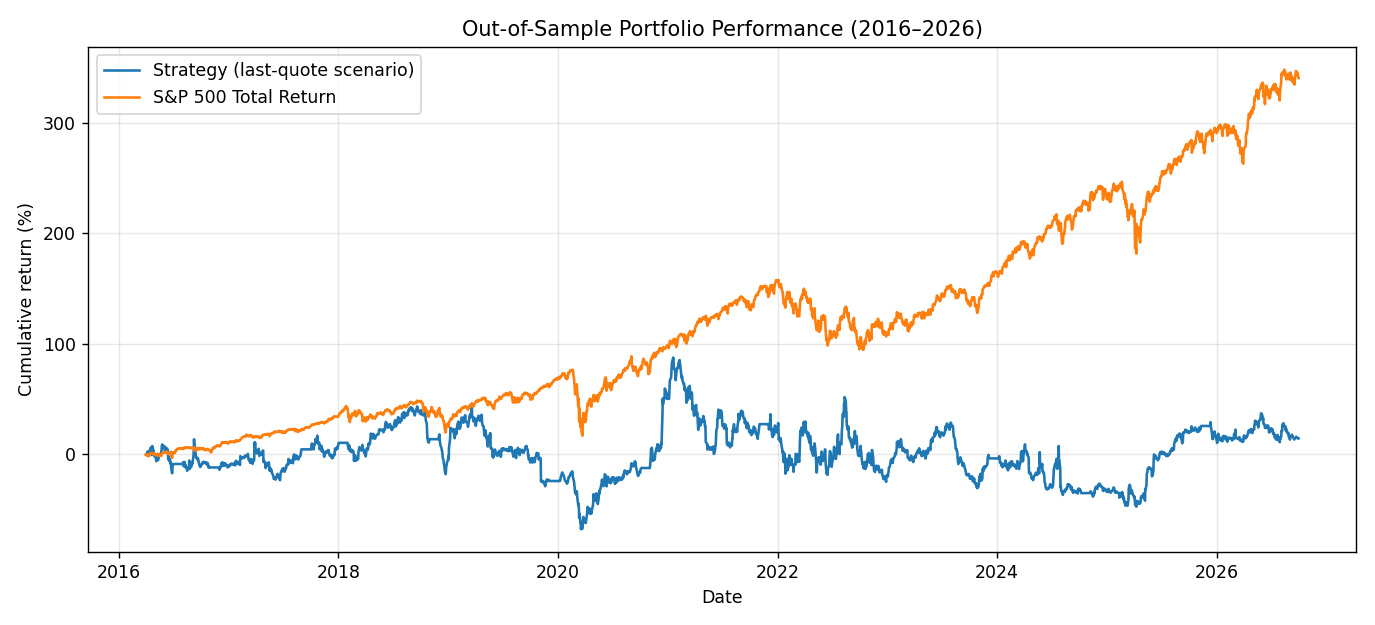

,Unresolved Value Retained,Final Portfolio Value,Total Return (%),Beats Benchmark
0,1.00,1145790.14,14.58,False
1,0.75,981245.96,-1.88,False
2,0.50,816701.79,-18.33,False
3,0.00,487613.44,-51.24,False


In [13]:
# Load S&P 500 Total Return benchmark
benchmark = full_con.execute("""
    SELECT date, adj_close
    FROM benchmark
    WHERE symbol = '^SP500TR'
    ORDER BY date
""").df()

benchmark["date"] = pd.to_datetime(benchmark["date"])

performance = scenario_portfolio.merge(
    benchmark, on="date", how="left"
)

# Benchmark starts with the same $1 million
performance["benchmark_value"] = (
    initial_cash
    * performance["adj_close"]
    / performance["adj_close"].iloc[0]
)

assert performance[
    ["portfolio_value", "benchmark_value"]
].notna().all().all()

def performance_metrics(values, dates):
    values = values.astype(float)
    returns = values.pct_change(fill_method=None).dropna()

    years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    daily_rf = (1.02 ** (1 / 252)) - 1

    return {
        "Final Value ($)": values.iloc[-1],
        "Total Return (%)": 100 * (values.iloc[-1] / values.iloc[0] - 1),
        "CAGR (%)": 100 * ((values.iloc[-1] / values.iloc[0]) ** (1 / years) - 1),
        "Max Drawdown (%)": 100 * (values / values.cummax() - 1).min(),
        "Sharpe Ratio": (
            np.sqrt(252) * (returns - daily_rf).mean()
            / returns.std()
        )
    }

metrics = pd.DataFrame({
    "Strategy (last-quote scenario)": performance_metrics(
        performance["portfolio_value"], performance["date"]
    ),
    "S&P 500 Total Return": performance_metrics(
        performance["benchmark_value"], performance["date"]
    )
}).T

display(metrics.round(2))

plt.figure(figsize=(11, 5))

plt.plot(
    performance["date"],
    100 * (performance["portfolio_value"] / initial_cash - 1),
    label="Strategy (last-quote scenario)"
)

plt.plot(
    performance["date"],
    100 * (performance["benchmark_value"] / initial_cash - 1),
    label="S&P 500 Total Return"
)

plt.title("Out-of-Sample Portfolio Performance (2016–2026)")
plt.xlabel("Date")
plt.ylabel("Cumulative return (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

unresolved_value = unresolved_df["last_quote_value"].sum()

scenario_final = scenario_portfolio["portfolio_value"].iloc[-1]
benchmark_final = performance["benchmark_value"].iloc[-1]

sensitivity = pd.DataFrame({
    "Unresolved Value Retained": [1.00, 0.75, 0.50, 0.00]
})

sensitivity["Final Portfolio Value"] = (
    scenario_final
    - unresolved_value * (1 - sensitivity["Unresolved Value Retained"])
)

sensitivity["Total Return (%)"] = (
    sensitivity["Final Portfolio Value"] / initial_cash - 1
) * 100

sensitivity["Beats Benchmark"] = (
    sensitivity["Final Portfolio Value"] > benchmark_final
)

print("Scenario sensitivity to unresolved positions:")
display(sensitivity.round(2))

gap = scenario_final - benchmark_final
scenario_return = 100 * (scenario_final / initial_cash - 1)
benchmark_return = 100 * (benchmark_final / initial_cash - 1)
print(f"Ending value relative to benchmark: {gap:+,.2f} dollars")
print(f"Cumulative return relative to benchmark: {scenario_return - benchmark_return:+.2f} percentage points")
print(f"Flagged price events while holding: {len(final_jump_events)}")

## 6. Findings, limitations, and reproducibility

In the corrected full-database run, the strategy ended at **$1,145,790.14** under last-quote marking, versus **$4,402,746.78** for the benchmark. It trailed by **$3,256,956.64**, or **325.70 percentage points** of cumulative return. The strategy's CAGR was 1.30% versus 15.17%, maximum drawdown was −77.38% versus −33.79%, and Sharpe was 0.22 versus 0.77. The strategy had deeper losses from its peaks and earned less per unit of daily volatility.

The primary valuation was unavailable on 659 of 2,640 sessions. Nine positions remained at the end, including four with unresolved marks (LTHM, BSGM, MFH, and CIFRW). Their last-quote marks account for $658,176.69 of the scenario's ending value. Reducing those marks to 75% lowers the scenario to $981,245.96. The strategy trails the benchmark across all four ending-value scenarios. The run recorded one flagged price event while holding.

The 2014 holdout favored the forest over Ridge, but the classroom ranking signal was weak. The portfolio can concentrate in a handful of stocks and in overlapping industry exposures. A per-name cap based on total portfolio value and a simple momentum baseline are two changes I would test on development data.

Unresolved quotes can affect the comparison, especially when a large position stops trading. The data guide documents incomplete ticker histories and limited delisting information. A missing quote gives no basis for booking proceeds. A last-quote mark can overstate or understate eventual value. Even positive adjusted quotes can reflect inconsistent corporate-action adjustments. The price-jump heuristic can remove real events and miss smaller errors. Labels with no observed exit do not enter training, which can bias the fitted model toward names with better price coverage. Fractional adjusted-price units and flat trading fees simplify execution and omit bid-ask spreads and market impact.

**Sources and assistance.** I used the course DuckDB files and the course data guide for the data schema, membership timing, and audit examples. The notebook uses its own backtest loop and does not call the Lecture 8 backtester. ChatGPT helped structure, debug, document, and revise the notebook, including the calendar alignment, order timing checks, and presentation of results.

[Course modeling data guide](https://github.com/yang-guo/UCB-MFE-python-preprogram-2026-winter/blob/main/Lectures/modeling/README.md)